# Compatability with transitleastsquares
The transitleastsquares module (Michael Hippke & René Heller 2019) can be called as an option through the BLS functionality. The transitleastsquares module has been configured to use the same input object as BLS, and additional parameters can be specified through the pars attribute. Note that these will override the default fixing of the duration grid.

EDIT: the newest version of transitleastsquares (2.0.1) has been incorporated at the time of this writing. 

In [1]:
import os
import numpy as np
import pandas as pd

homedir = os.getcwd()
import pytfit5.bls_cpu as gbls
import pytfit5.pipefuncs as pipe
import pytfit5.transitPy5 as tpy5
from pytfit5.synthetic import generate_synthetic_lightcurve

## Synthetic Light-Curves
TLS is called with the tls function rather than the bls_pulse function. The synthetic light curve uses parameters very similar to the pytfit5_example notebook; the period, T0, snr and depth are occasionally modified to highlight a specific goal/purpose, which wil be discussed. 

### Testing for a Pulse
TLS is not configured to detect a singular transit or a pulse. If we allow for its default limits, then it searches for half the timespan, i.e. two transits as minimum (bls_periodic does this as well). 

Note! The warning about the period grid density (if present) comes from TLS's warmup.py, where they create a time array of 20 days and 3000 points. This is different from what is actually searched and can be safely ignored.

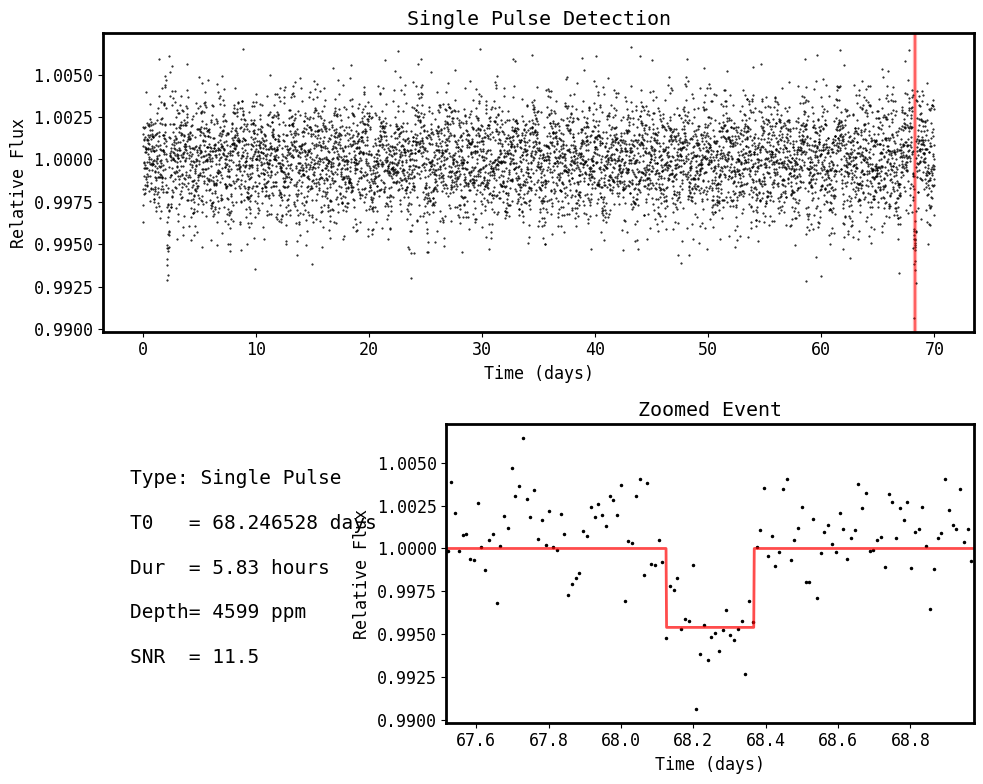

{'M_star': np.float64(1.0),
 'M_star_max': np.float64(1.2),
 'M_star_min': np.float64(0.19999999999999996),
 'R_star': np.float64(1.0),
 'R_star_max': np.float64(1.2),
 'R_star_min': np.float64(0.19999999999999996),
 'n_transits_min': 2,
 'period_min': 0.5,
 'u': [0.4804, 0.1867]}


/home/sliu/tls_env/lib/python3.13/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


Transit Least Squares TLS 2.0.1 (11 Oct 2026)
Creating model cache for 45 durations
Searching 6721 data points, 7324 periods from 0.601 to 35.0 days
Using all 20 CPU threads


100%|██████████| 7324/7324 periods | 00:01<00:00


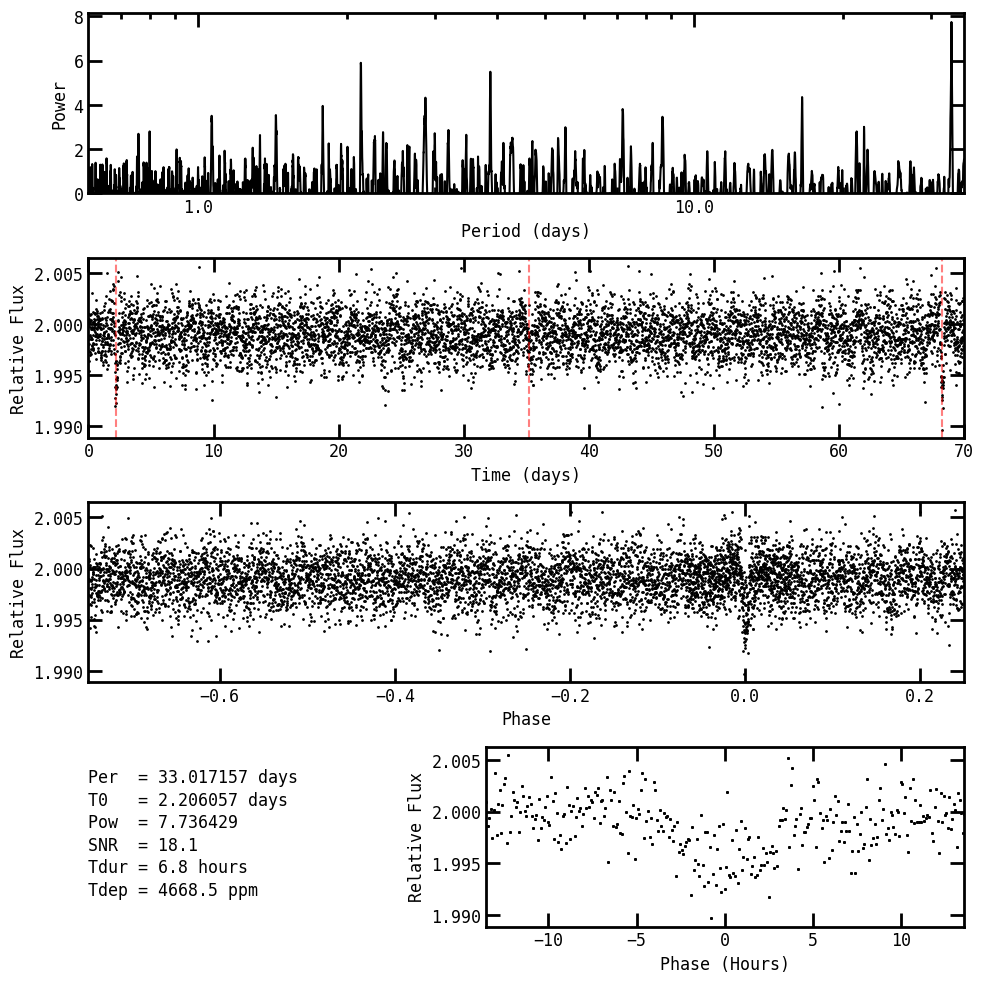

In [2]:
# Only the period is changed from the pytfit5 notebook - 10 days longer.
phot_syn, sol_injected = generate_synthetic_lightcurve(
    t0=2.2, per=66.05, time_length=70.0, depth=0.005, \
    snr=20.0, cadence=1.0/96.0, stellar_noise_type='multi', \
    stellar_noise_amplitude=0.005, rotation_period=None, seed=42)

# Configuring BLS and TLS for the synthetic data
# Removing those which are set by default appropriately, e.g zerotime, stellar parameters, etc.
synputs = tpy5.tpy5_inputs_class()
synputs.filename = "BLS_Synthetic"
# Data-processing is changed to 3 days detrending instead of the usual two.
synputs.boxbin = 3.0  # set detrending length
synputs.boxbin = 3.0  # set detrending length
synputs.search_verbose = True # for tls to spit out its parameters and search info
tpy5.run_polyfilter_iterative(phot_syn, synputs)   # flux_f will contain filtered photometry

# Run the BLS pulse search instead of the periodic functionality.
bsyn = gbls.bls_pulse(synputs, phot_syn.time, phot_syn.flux_f)
# Run TLS for a comparison to BLS
tsyn = gbls.tls(synputs, phot_syn.time, phot_syn.flux_f, phot_syn.ferr)

{'M_star': np.float64(1.0),
 'M_star_max': np.float64(1.2),
 'M_star_min': np.float64(0.19999999999999996),
 'R_star': np.float64(1.0),
 'R_star_max': np.float64(1.2),
 'R_star_min': np.float64(0.19999999999999996),
 'n_transits_min': 2,
 'period_min': 0.5,
 'u': [0.4804, 0.1867]}
Transit Least Squares TLS 2.0.1 (11 Oct 2026)
Creating model cache for 43 durations
Searching 5761 data points, 6163 periods from 0.601 to 30.0 days
Using all 20 CPU threads


100%|██████████| 6163/6163 periods | 00:00<00:00


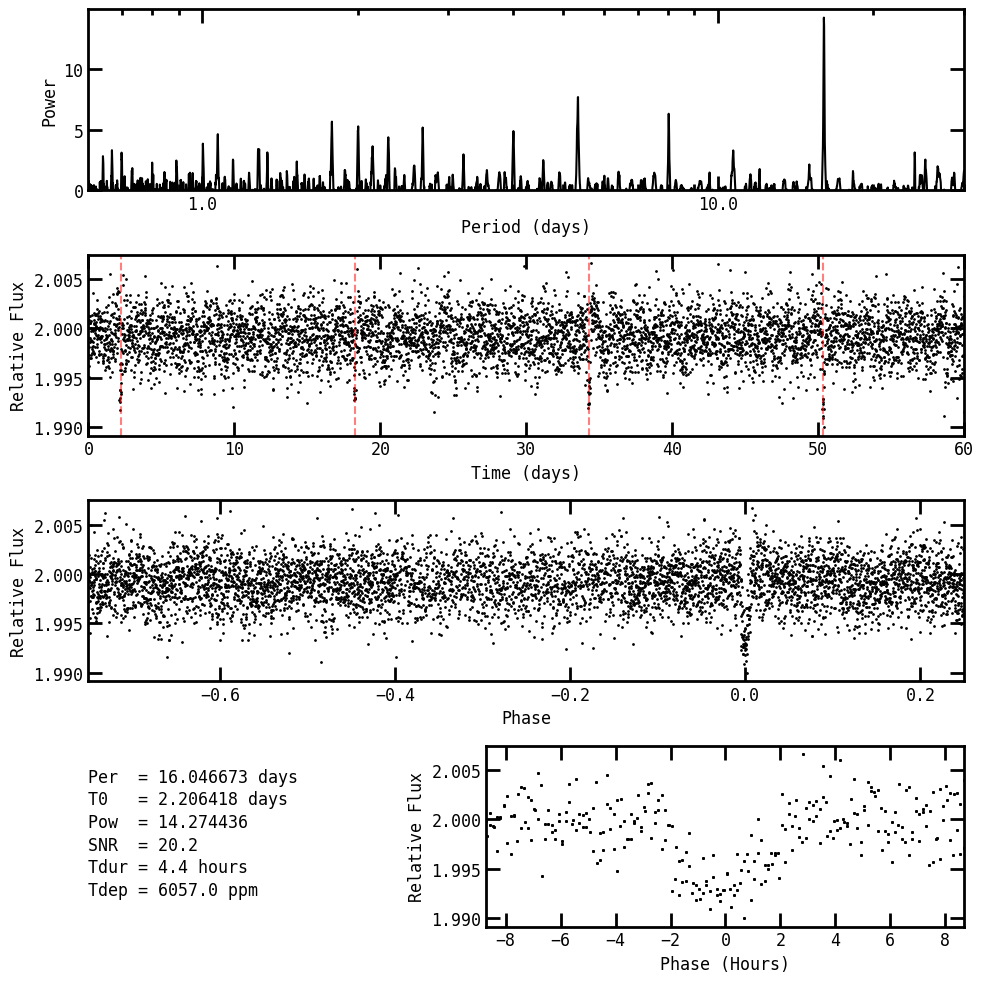

In [3]:
# Changing the period to shorter for easier detection by TLS.
phot_syn, sol_injected = generate_synthetic_lightcurve(
    t0=2.2, per=16.05, time_length=60.0, depth=0.005, \
    snr=20.0, cadence=1.0/96.0, stellar_noise_type='multi', \
    stellar_noise_amplitude=0.005, rotation_period=None, seed=42)
tpy5.run_polyfilter_iterative(phot_syn, synputs)
tsyn = gbls.tls(synputs, phot_syn.time, phot_syn.flux_f, phot_syn.ferr)

## Roman Simulated Light-curves with Stellar Parameters
Because we have specified stellar parameters and limb-darkening from these simulated light-curves, this offers a useful measure to assess the performance of `transitleastsquares`! To do so, we call pipeline functions in `pipefuncs.py`, which offer us an easy way to access these light-curves.

In [4]:
LCDIR = '/home/sliu/data/rlc'
def runinstance(ric):
    '''
    To run a single occurrence, i.e. to run a single RIC.
    '''
    # Creating our input class and loading photometric data.
    roput = tpy5.tpy5_inputs_class()
    roput.zerotime = pipe.ROMANOFF
    phot = pipe.read2Phot(f'{LCDIR}/{int(ric)}/raw.h5')
    ## Data Processing
    roput.boxbin, roput.dsigclip = 3.0, 0
    roput.search_verbose = True 
    m = pipe.processData(phot, roput) # detrending/clipping
    t, f, err = phot.time[m], phot.flux_f[m], phot.ferr[m]
    
    ## Fetching the Stellar Parameters!
    starRow = pipe.getRICRow(ric, pipe.cat)
    roput.rstar = float(starRow['star_radius'])
    roput.mstar = float(starRow['star_mass'])
    roput.u = starRow[['transit_limb1_F146', 'transit_limb2_F146']].values
    
    brom = gbls.bls_periodic(roput, phot.time, phot.flux_f)
    trom = gbls.tls(roput, phot.time, phot.flux_f, phot.ferr)

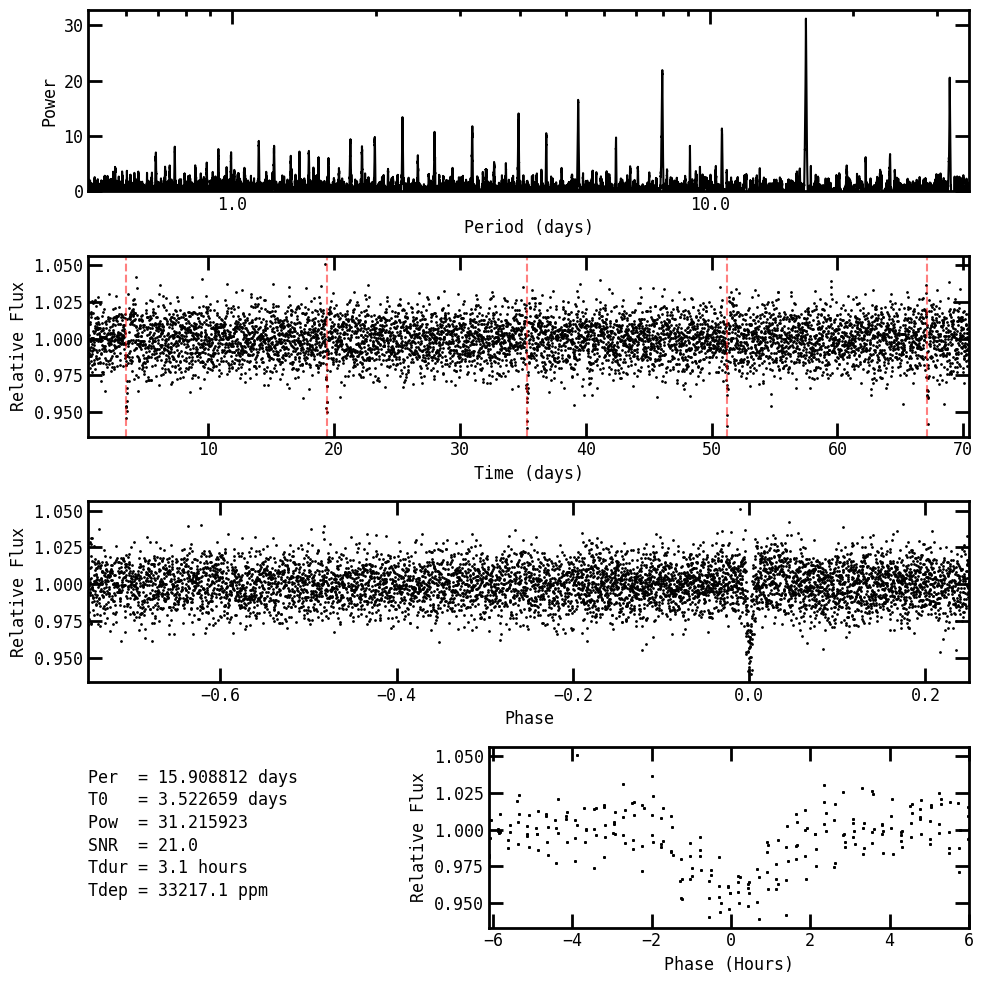

{'M_star': np.float64(0.599),
 'M_star_max': np.float64(0.7188),
 'M_star_min': np.float64(0.11979999999999996),
 'R_star': np.float64(0.557),
 'R_star_max': np.float64(0.6684),
 'R_star_min': np.float64(0.11139999999999999),
 'n_transits_min': 2,
 'period_min': 0.5,
 'u': array([0.1502, 0.3388])}
Transit Least Squares TLS 2.0.1 (11 Oct 2026)
Creating model cache for 47 durations
Searching 6595 data points, 12030 periods from 0.5 to 34.994 days
Using all 20 CPU threads


100%|██████████| 12030/12030 periods | 00:01<00:00


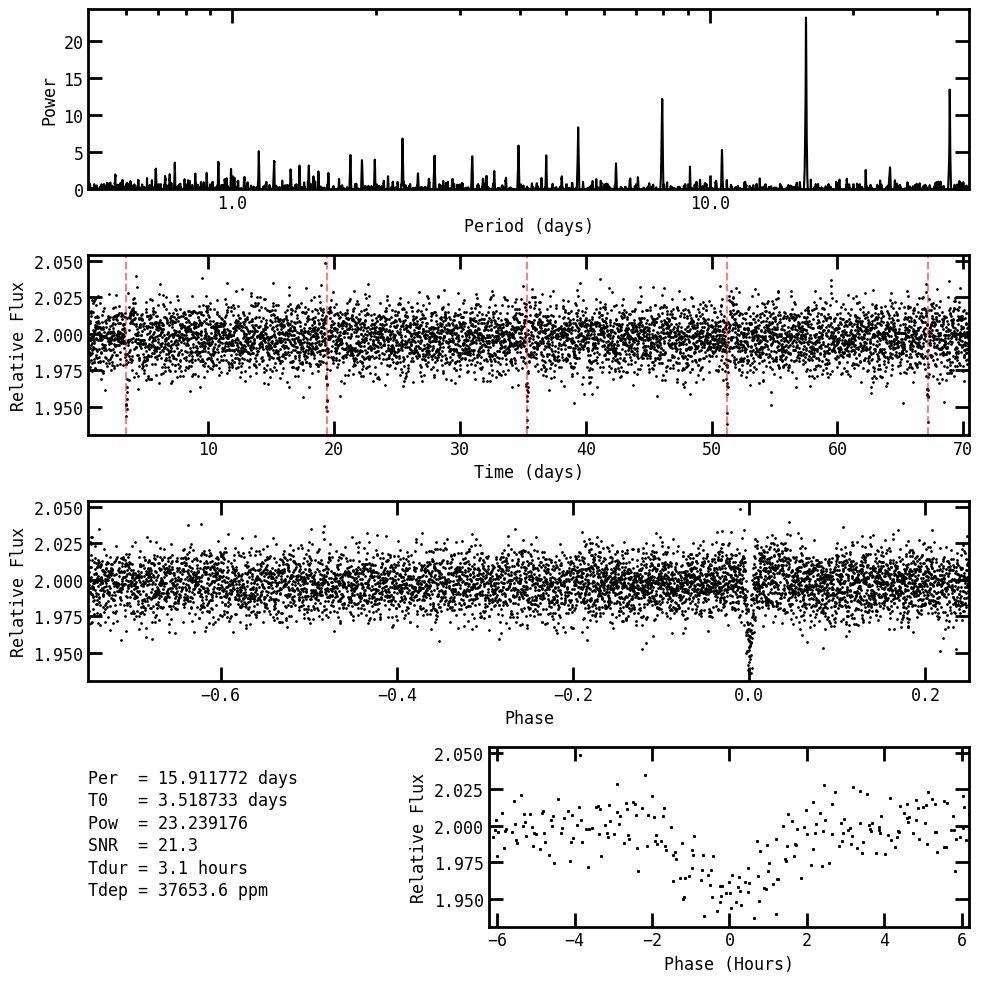

In [5]:
runinstance(121833)

### Pipeline Functionality
For the Roman simulated lightcurves (in `/data/rlc`), we want to be able to iterate through them and save the outputs in order to consider the efficiency of `transitleastsquares` versus `bls_periodic`. What the pipeline must consider:
- Iterating through various RICs (the Roman Input Catalogue) and reading in their stellar parameters.
- Multiple transiting planets: we "swiss-cheese" to remove the transiting planets detected.
- Writing and saving the data to a dataframe for various output columns.

For an apples-to-apples comparison, we neglect the pulse search within `bls_cuda` for now.

In [6]:
roput = pipe.pipelineIns()
roput.plots = 0
roput.lcdir = LCDIR
roput.filename = ''
roput.zerotime = pipe.ROMANOFF
roput.rics = pipe.starID[800:805]
roput.boxbin, roput.dsigclip = 3.0, 0
roput.blsfunc = gbls.bls_periodic
roput.savedir = '/home/sliu/data/demo-run'

pipe.main(roput)

Starting RIC: 2564, which is number: 0!


100%|██████████| 20052/20052 periods | 00:01<00:00
100%|██████████| 20052/20052 periods | 00:00<00:00
100%|██████████| 20052/20052 periods | 00:01<00:00


Starting RIC: 2565, which is number: 1!


100%|██████████| 19714/19714 periods | 00:01<00:00


Starting RIC: 2573, which is number: 2!


...

Starting RIC: 2574, which is number: 3!


100%|██████████| 24071/24071 periods | 00:01<00:00
100%|██████████| 24071/24071 periods | 00:01<00:00


Starting RIC: 2575, which is number: 4!


100%|██████████| 24071/24071 periods | 00:01<00:00
100%|██████████| 24071/24071 periods | 00:01<00:00
/home/sliu/tls_env/lib/python3.13/site-packages/transitleastsquares/stats.py:735: RuntimeWarning: divide by zero encountered in scalar divide
  snr_pink_per_transit[i] = (1 - mean_flux) / pinknoise


Finished! Saving (just in case) again.


In [13]:
bdf = pd.read_csv(roput.savedir('bls', 0))
tdf = pd.read_csv(roput.savedir('tls', 0))
pd.concat([tdf.head(), bdf.head()], keys=['TLS', 'BLS'])

RIC     Period        T0      TDur    TDepth     RawPer   SR  \
TLS 0  2564.0   2.052153  2.389061  0.026011  0.013623   2.052153  0.0   
    1  2564.0  25.274737  4.628698  0.135333  0.013792  34.653109  0.0   
    2  2564.0   1.097516  0.872275  0.026303  0.003600   8.231719  0.0   
    3  2565.0   4.528848  3.751360  0.036608  0.007094  28.252744  0.0   
    4  2573.0  19.569244  1.814691  0.036181  0.049624  19.569244  0.0   
BLS 0  2564.0   2.052064  2.388397  0.025651  0.013714   2.052064  NaN   
    1  2564.0   3.950830  0.692588  0.100746  0.003484  34.680850  NaN   
    2  2565.0   1.412704  1.661933  0.035318 -0.004617   1.412704  NaN   
    3  2573.0   3.528469  1.165983  0.026464 -0.014458  19.572492  NaN   
    4  2574.0   3.079516  0.831803  0.038494  0.011670   3.079516  NaN   

           Power        SNR       Time  
TLS 0  27.924304  11.959254   1.177407  
    1   8.234704   7.955620   1.093929  
    2   7.102073   3.731135   1.117344  
    3   6.360281   4.821177   1.278231  
    4   8.066417   5.758342   2.145002  
BLS 0  21.260842  12.287816  30.080435  
    1   6.579488   4.484959  29.001406  
    2   6.861245  -6.024800  28.687249  
    3   6.094311  -3.830940  36.647576  
    4  10.241403   6.989247  35.583131

### Recovery! 
We can double-check how our outputs compare to the simulated catalogue via the recovery function, i.e. this looks at completion. We remove the negative SNR rows from the BLS output because they have negative transit depth.

In [16]:
allcat = pd.read_csv('/home/sliu/data/planet_cat.csv')
cat = (allcat).copy()[np.isin((allcat).star_id, tdf.RIC)]
bdf = bdf[bdf.SNR > 0]
brec = pipe.getrec(bdf, cat, verbose=True, rlcdir=LCDIR)
trec = pipe.getrec(tdf, cat, verbose=True, rlcdir=LCDIR)
pd.concat([trec.head(), brec.head()], keys=['TLS', 'BLS'])

health bar <3: 100%|██████████| 5/5 [00:00<00:00, 37.25it/s]


The number of recoverable ROIs is 5; the number of recovered ROIs is 3.


health bar <3: 100%|██████████| 8/8 [00:00<00:00, 40.88it/s]


The number of recoverable ROIs is 8; the number of recovered ROIs is 3.


Period        T0      TDur     RawPer    TDepth        SNR  \
    planet_id                                                                  
TLS 2564.01     2.052153  2.389061  0.026011   2.052153  0.013623  11.959254   
    2573.01    19.569244  1.814691  0.036181  19.569244  0.049624   5.758342   
    2574.01     3.079344  0.838087  0.035475   3.079344  0.012772   6.480159   
    2574.01     0.996901  0.656033  0.032320   0.996901  0.006033   5.250930   
    2575.02    32.235504  6.615638  0.066705  32.235504  0.102450   8.726048   
BLS 2564.01     2.052064  2.388397  0.025651   2.052064  0.013714  12.287816   
    2574.01     3.079516  0.831803  0.038494   3.079516  0.011670   6.989247   
    2574.01     0.996890  0.655001  0.031900   0.996890  0.005936   5.827763   
    2575.02    32.246408  6.594556  0.064493  32.246408  0.093113   9.411502   

               overlap_fraction  precision  true_positive  false_positive  \
    planet_id                                                               
TLS 2564.01            0.963303   0.990566            105               1   
    2573.01            0.375000   0.250000              6              18   
    2574.01            0.904762   0.894118             76               9   
    2574.01            0.011905   0.005814              1             171   
    2575.02            0.944444   0.894737             17               2   
BLS 2564.01            0.908257   0.951923             99               5   
    2574.01            0.940476   0.908046             79               8   
    2574.01            0.011905   0.006024              1             165   
    2575.02            0.944444   0.894737             17               2   

               false_negative  period_factor period_factor_type  is_recovered  \
    planet_id                                                                   
TLS 2564.01                 4              1              exact          True   
    2573.01                10              2           fraction         False   
    2574.01                 8              1              exact          True   
    2574.01                83              3           fraction         False   
    2575.02                 1              1              exact          True   
BLS 2564.01                10              1              exact          True   
    2574.01                 5              1              exact          True   
    2574.01                83              3           fraction         False   
    2575.02                 1              1              exact          True   

                best  
    planet_id         
TLS 2564.01     True  
    2573.01     True  
    2574.01     True  
    2574.01    False  
    2575.02     True  
BLS 2564.01     True  
    2574.01     True  
    2574.01    False  
    2575.02     True